# Imports

In [6]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:95% !important; }</style>"))
import warnings
warnings.filterwarnings("ignore") # umap deprecation warnings related to numba do not concern us.

In [7]:
import functools as fn
import itertools as it

import numpy as np
import pandas as pd

import sklearn
from sklearn.utils import Bunch
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.manifold import TSNE
from sklearn.preprocessing import FunctionTransformer
from umap import umap_ as umap

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import plotnine as pn
from plotnine import *

In [8]:
import scanpy as sc

from scboolseq.utils import parse_data_directory, parse_pickles
from scboolseq import scBoolSeq

In [2]:
# Source - https://stackoverflow.com/a/52858398
# Posted by user4234032, modified by community. See post 'Timeline' for change history
# Retrieved 2026-04-22, License - CC BY-SA 4.0

import os
notebook_path = os.path.abspath("1. Clusterization.ipynb")

In [4]:
%ls *csv

dataset_hvgs.csv  sc_metadata.csv


## HVG binarization

In [9]:
data = pd.read_csv("dataset_hvgs.csv", index_col=0)
print(data.shape)
data.head()

(14915, 481)


,1700020L24Rik,2810417H13Rik,4930519L02Rik,A230065H16Rik,Abhd2,Ackr1,Acp5,Adgrg3,Aif1,Alcam,...,Zfpm1,Tal1,Fli1,Ikzf1,Srf,Irf9,Zbtb16,Kdm5b,Foxp1,Bclaf1
AAACCTGAGTTCGATC-1_0,0.0,0.00000,0.000000,0.0,0.00000,0.0,4.576296,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.00000,0.000000,0.000000
AAACCTGCAATCGGTT-1_0,0.0,0.00000,0.000000,0.0,0.00000,0.0,0.000000,0.0,0.0,4.655546,...,4.655546,4.655546,0.000000,0.000000,0.0,0.0,0.0,0.00000,0.000000,4.655546
AAACCTGCACACGCTG-1_0,0.0,0.00000,3.782335,0.0,0.00000,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,3.782335,0.0,0.0,0.0,0.00000,3.782335,3.782335
AAACCTGCACGGATAG-1_0,0.0,3.58937,4.268613,0.0,3.58937,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,3.589370,0.000000,0.000000,0.0,0.0,0.0,3.58937,4.669401,3.589370
AAACCTGCATCATCCC-1_0,0.0,0.00000,0.000000,0.0,0.00000,0.0,0.000000,0.0,0.0,0.000000,...,0.000000,0.000000,4.848762,0.000000,0.0,0.0,0.0,0.00000,3.765704,4.848762


In [10]:
%%time
scbool = scBoolSeq(
    dor_threshold=0.995, # To retain one of the markers, otherwise it will be marked as discarded due to its high dropout rate
    confidence=.75 # To maximize binarization
)
scbool.fit(data)

CPU times: user 1min 54s, sys: 701 ms, total: 1min 55s
Wall time: 11.6 s


,confidence,0.75
,covariance_type,'full'
,margin_quantile,0.05
,alpha,0.0
,zeroinf_binarizer,'zero_or_not'
,zeroes_are,nan
,dor_threshold,0.995
,amplitude_threshold,10.0
,half_life_parameter,'MeanNZ'
,warm_start,True
,require_df,True


In [11]:
scbool.criteria_.Category.value_counts()

Category
ZeroInf    322
Bimodal    159
Name: count, dtype: int64

In [12]:
from markers import (
    positive_markers, # function to generate a configuration dictionnary from a set of marker genes
    states_and_markers, # Dictionnary containing phenotypes and their marker genes
)

marker_genes = pd.Series(list(set(it.chain.from_iterable(states_and_markers.values()))))
marker_genes.shape[0]

23

In [13]:
scbool.criteria_.loc[marker_genes, :].Category.value_counts()

Category
Bimodal    16
ZeroInf     7
Name: count, dtype: int64

In [14]:
%time bin_data = scbool.binarize(data)

CPU times: user 596 ms, sys: 27.9 ms, total: 624 ms
Wall time: 625 ms


In [15]:
partial_bin_configs = bin_data[marker_genes]
partial_bin_configs.fillna('').head()

,Myc,Gata2,Stat1,Fli1,Foxp1,Junb,Cebpa,Zfpm1,Sox4,Irf1,...,Spi1,Ikzf1,Zbtb16,Egr1,Bclaf1,Klf1,Hoxa9,Tal1,Irf7,Irf9
AAACCTGAGTTCGATC-1_0,0.0,0.0,0.0,0.0,0.0,0.0,,,1.0,0.0,...,1.0,0.0,,0.0,0.0,,0.0,0.0,,0.0
AAACCTGCAATCGGTT-1_0,1.0,1.0,0.0,0.0,0.0,1.0,,1.0,1.0,0.0,...,1.0,0.0,,0.0,1.0,,1.0,1.0,,0.0
AAACCTGCACACGCTG-1_0,0.0,0.0,0.0,0.0,1.0,0.0,,,1.0,0.0,...,0.0,1.0,,0.0,1.0,,0.0,0.0,,0.0
AAACCTGCACGGATAG-1_0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,,1.0,0.0,...,1.0,0.0,,0.0,1.0,,0.0,1.0,,0.0
AAACCTGCATCATCCC-1_0,1.0,0.0,1.0,1.0,1.0,1.0,,,1.0,0.0,...,1.0,0.0,,0.0,1.0,,0.0,0.0,,0.0


In [16]:
prior_markers = {
    obs: positive_markers(markers)
    for obs, markers
    in states_and_markers.items()
}
prior_markers

{'iHSC': {'Srf': 1, 'Foxp1': 1, 'Fli1': 1, 'Kdm5b': 1, 'Bclaf1': 1},
 'srHSC': {'Srf': 1, 'Bclaf1': 1},
 'ifnHSC': {'Irf9': 1, 'Irf7': 1, 'Stat1': 1, 'Irf1': 1},
 'qHSC': {'Tal1': 1, 'Gata2': 1, 'Junb': 1, 'Fli1': 1, 'Egr1': 1},
 'preDiff': {'Spi1': 1, 'Myc': 1, 'Sox4': 1, 'Hoxa9': 1},
 'pLymph': {'Ikzf1': 1, 'Zbtb16': 1},
 'pNeuMast': {'Cebpa': 1, 'Spi1': 1},
 'pEr': {'Klf1': 1, 'Zfpm1': 1, 'Gata1': 1},
 'pMk': {'Fli1': 1, 'Zfpm1': 1, 'Gata1': 1}}

In [17]:
obs_by_markers = {}
for _conf, _marker_dict in prior_markers.items():
    # Build a query with the genes and their values, configuration by configuration
    _conf_query = " & ".join(f"{_gene} == {_value:.1f}" for _gene, _value in _marker_dict.items())
    _matching = partial_bin_configs.fillna(-1.0).query(_conf_query).index
    obs_by_markers.update({_conf: _matching})

In [18]:
number_of_matching_obs = {conf: idx.shape[0] for conf, idx in obs_by_markers.items()}
number_of_matching_obs

{'iHSC': 38,
 'srHSC': 430,
 'ifnHSC': 143,
 'qHSC': 399,
 'preDiff': 1144,
 'pLymph': 178,
 'pNeuMast': 521,
 'pEr': 95,
 'pMk': 136}

In [19]:
percentage_matching = {conf: 100*idx.shape[0]/partial_bin_configs.shape[0] for conf, idx in obs_by_markers.items()}
{k: f"{v:.2f}" for k, v in percentage_matching.items()}

{'iHSC': '0.25',
 'srHSC': '2.88',
 'ifnHSC': '0.96',
 'qHSC': '2.68',
 'preDiff': '7.67',
 'pLymph': '1.19',
 'pNeuMast': '3.49',
 'pEr': '0.64',
 'pMk': '0.91'}

In [20]:
int(sum(percentage_matching.values()))

20

## Check for multi-labelled cells

In [22]:
intersections_of_all_combinations = list(map(
    lambda x: (
        x, 
        obs_by_markers[x[0]].intersection(obs_by_markers[x[1]]).shape[0]
    ), 
    it.combinations(obs_by_markers, 2) # All possible pairwise combinations, without replacement
)) # This will contain a list of nested tuples as follows: ((conf_1, conf_2), number_of_cells_in_both_groups)

In [23]:
non_null_intersections = list(filter(
    lambda p1_p2_shape: p1_p2_shape[-1].shape[0] > 0,
    map(
        lambda x: (x, obs_by_markers[x[0]].intersection(obs_by_markers[x[1]])), 
        it.combinations(obs_by_markers, 2)
    )
))
print(len(non_null_intersections))
len(non_null_intersections) / len(intersections_of_all_combinations)

34


0.9444444444444444

In [24]:
{(c1, c2): len(idx) for ((c1, c2), idx) in non_null_intersections}

{('iHSC', 'srHSC'): 38,
 ('iHSC', 'ifnHSC'): 1,
 ('iHSC', 'qHSC'): 6,
 ('iHSC', 'preDiff'): 7,
 ('iHSC', 'pLymph'): 2,
 ('iHSC', 'pNeuMast'): 4,
 ('iHSC', 'pMk'): 2,
 ('srHSC', 'ifnHSC'): 4,
 ('srHSC', 'qHSC'): 20,
 ('srHSC', 'preDiff'): 62,
 ('srHSC', 'pLymph'): 9,
 ('srHSC', 'pNeuMast'): 21,
 ('srHSC', 'pEr'): 6,
 ('srHSC', 'pMk'): 11,
 ('ifnHSC', 'qHSC'): 7,
 ('ifnHSC', 'preDiff'): 21,
 ('ifnHSC', 'pLymph'): 2,
 ('ifnHSC', 'pNeuMast'): 5,
 ('ifnHSC', 'pMk'): 1,
 ('qHSC', 'preDiff'): 55,
 ('qHSC', 'pLymph'): 3,
 ('qHSC', 'pNeuMast'): 13,
 ('qHSC', 'pEr'): 3,
 ('qHSC', 'pMk'): 11,
 ('preDiff', 'pLymph'): 19,
 ('preDiff', 'pNeuMast'): 132,
 ('preDiff', 'pEr'): 12,
 ('preDiff', 'pMk'): 13,
 ('pLymph', 'pNeuMast'): 20,
 ('pLymph', 'pEr'): 1,
 ('pLymph', 'pMk'): 2,
 ('pNeuMast', 'pEr'): 4,
 ('pNeuMast', 'pMk'): 7,
 ('pEr', 'pMk'): 39}

In [25]:
unambiguous_observations = {}
for _phenotype, _idx in obs_by_markers.items():
    _unambiguous = fn.reduce(
        lambda x, y: x.difference(y),
        [idx for ((p1, p2), idx) in non_null_intersections if p1 == _phenotype or p2 == _phenotype],
        _idx
    )
    unambiguous_observations.update({_phenotype: _unambiguous})
    _n_unambiguous = _unambiguous.shape[0]
    print(f"{_phenotype} has {_n_unambiguous} matching unambiguous configurations, {100*_n_unambiguous/number_of_matching_obs[_phenotype]:.2f}% of matching configs")
    
unlabelled_idx = data.index.difference(fn.reduce(lambda x, y: x.union(y), unambiguous_observations.values()))

iHSC has 0 matching unambiguous configurations, 0.00% of matching configs
srHSC has 298 matching unambiguous configurations, 69.30% of matching configs
ifnHSC has 110 matching unambiguous configurations, 76.92% of matching configs
qHSC has 305 matching unambiguous configurations, 76.44% of matching configs
preDiff has 868 matching unambiguous configurations, 75.87% of matching configs
pLymph has 131 matching unambiguous configurations, 73.60% of matching configs
pNeuMast has 350 matching unambiguous configurations, 67.18% of matching configs
pEr has 42 matching unambiguous configurations, 44.21% of matching configs
pMk has 68 matching unambiguous configurations, 50.00% of matching configs


In [26]:
color_map = {
    "Unknown": "#e6e6e6",   # gray
    "iHSC": "#1f77b4",      # blue
    "srHSC": "#17becf",     # light blue / cyan
    "ifnHSC": "#9467bd",    # purple
    "qHSC": "#2ca02c",      # green
    "preDiff": "#ff7f0e",   # orange
    "pLymph": "#e377c2",    # pink
    "pNeuMast": "#8c564b",  # brown
    "pEr": "#d62728",       # red
    "pMk": "#bcbd22",       # olive
}

In [27]:
unambiguous_metadata = pd.DataFrame({
    "label": "Unknown"
}, index=data.index)
for _conf, _idx in unambiguous_observations.items():
    unambiguous_metadata.loc[_idx, "label"] = _conf

color = unambiguous_metadata.label.map(color_map)
color.name = "label_color"
unambiguous_metadata = unambiguous_metadata.join(color)

print(100 * unambiguous_metadata.label.value_counts() / unambiguous_metadata.shape[0])
unambiguous_metadata.head()

label
Unknown     85.437479
preDiff      5.819645
pNeuMast     2.346631
qHSC         2.044921
srHSC        1.997989
pLymph       0.878310
ifnHSC       0.737513
pMk          0.455917
pEr          0.281596
Name: count, dtype: float64


,label,label_color
AAACCTGAGTTCGATC-1_0,Unknown,#e6e6e6
AAACCTGCAATCGGTT-1_0,preDiff,#ff7f0e
AAACCTGCACACGCTG-1_0,Unknown,#e6e6e6
AAACCTGCACGGATAG-1_0,pNeuMast,#8c564b
AAACCTGCATCATCCC-1_0,Unknown,#e6e6e6


In [28]:
unambiguous_metadata.query("label != 'Unknown'").shape[0] / unambiguous_metadata.shape[0]

0.14562520952061683

In [29]:
EXPORT_METADATA = True

if EXPORT_METADATA:
    (
        unambiguous_metadata
            .query("label != 'Unknown'")
            .rename(columns={"label": "observation"})
            .observation
            .to_frame()
            .to_csv("scboolseq_inferred_observations.csv")
    )
    #unambiguous_metadata.to_csv("GSE122466_unambiguous_metadata_batch1.csv")

In [103]:
N_PCS = 10

In [104]:
%%time
projection_pipeline = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('umap', umap.UMAP())
])
reduced_umap = projection_pipeline.fit_transform(data)
projected_umap = pd.DataFrame(reduced_umap, index=data.index)

CPU times: user 37 s, sys: 2.63 s, total: 39.6 s
Wall time: 5.63 s


In [105]:
%%time
projection_pipeline2 = Pipeline([
    ('pca', PCA()),
    ('subset_max_pcas', FunctionTransformer(lambda x: x.iloc[:, :N_PCS] if isinstance(x, pd.DataFrame) else x[:, :N_PCS])), 
    ('tsne', TSNE())
])
reduced_tsne = projection_pipeline2.fit_transform(data)
projected_tsne = pd.DataFrame(reduced_tsne, index=data.index)

CPU times: user 3min 54s, sys: 1.71 s, total: 3min 55s
Wall time: 56.3 s


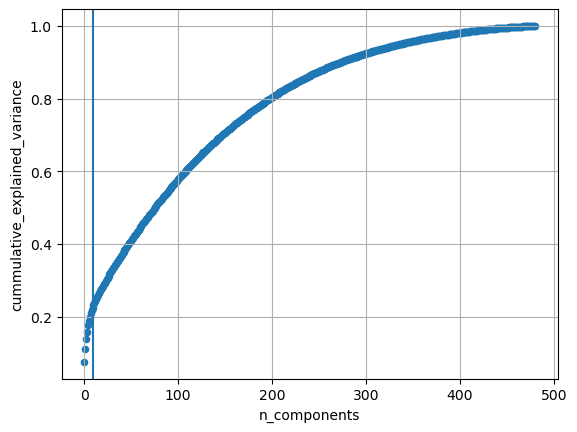

In [106]:
(
    pd.Series(projection_pipeline['pca'].explained_variance_ratio_)
        .cumsum()
        .to_frame()
        .reset_index()
        .rename(columns={'index': 'n_components', 0: 'cummulative_explained_variance'})
        .plot.scatter(x='n_components', y='cummulative_explained_variance')
)
plt.grid()
plt.axvline(N_PCS)

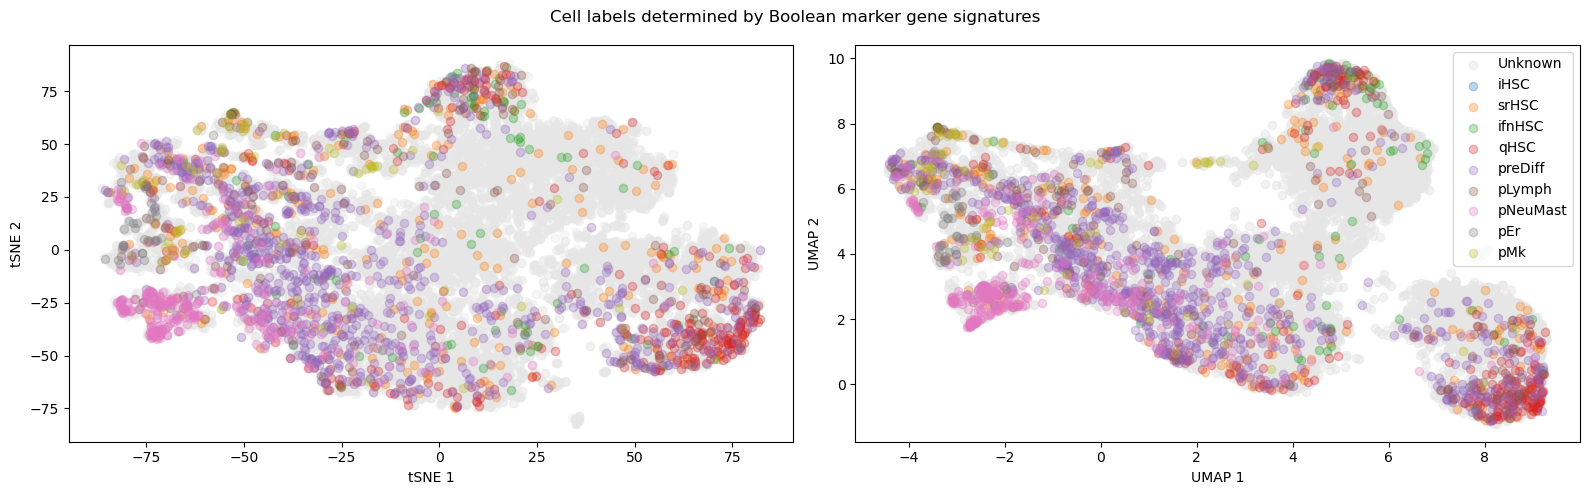

In [107]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16,5))

_tsne_i = 0
_umap_i = 1
_ = axs[_umap_i].scatter(projected_umap.loc[unlabelled_idx, 0], projected_umap.loc[unlabelled_idx, 1], label="Unknown", alpha=.5, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_umap.loc[idx, 0], projected_umap.loc[idx, 1]
        axs[_umap_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])

axs[_umap_i].set_xlabel("UMAP 1")
axs[_umap_i].set_ylabel("UMAP 2")
#axs[0].legend()

_xname = projected_tsne.columns[0]
_yname = projected_tsne.columns[1]
_ = axs[_tsne_i].scatter(projected_tsne.loc[unlabelled_idx, _xname], projected_tsne.loc[unlabelled_idx, _yname], label="Unknown", alpha=.3, c=color_map["Unknown"])
for name, idx in unambiguous_observations.items():
        _x, _y = projected_tsne.loc[idx, _xname], projected_tsne.loc[idx, _yname]
        axs[_tsne_i].scatter(_x, _y, label=name, alpha=1 if name == 'HC' else .3)#, c=color_map[name])
axs[_tsne_i].set_xlabel("tSNE 1")
axs[_tsne_i].set_ylabel("tSNE 2")
#axs[1].legend()
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys())

plt.suptitle("Cell labels determined by Boolean marker gene signatures")
fig.tight_layout()

In [108]:
isolated_cells = (
    projected_umap
        .rename(columns={c: f"umap_{c}" for c in projected_umap.columns})
        .query("umap_0 > umap_0.mean() & umap_1 < 0")
        .index
)

In [109]:
print(f"{100*isolated_cells.shape[0]/data.shape[0]:.1f}% of cells are in this region/cluster")

6.0% of cells are in this region/cluster


In [110]:
isolated_cells_labels: set = set()
for name, idx in unambiguous_observations.items():
    if isolated_cells.isin(idx).any():
        isolated_cells_labels.update({name})
        
isolated_cells_labels

{'ifnHSC', 'pLymph', 'pNeuMast', 'preDiff', 'qHSC', 'srHSC'}

## Clustering and label propagation

In [111]:
sc.__version__

'1.11.5'

In [112]:
adata = sc.AnnData(data, dtype=np.float64)
adata

AnnData object with n_obs × n_vars = 14915 × 481

In [113]:
sc.pp.pca(adata, n_comps=N_PCS)

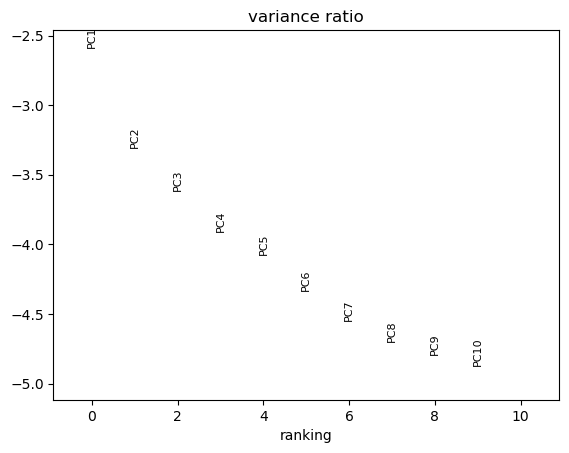

In [114]:
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=N_PCS)

In [115]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS)
adata

AnnData object with n_obs × n_vars = 14915 × 481
    uns: 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [116]:
sc.tl.louvain(adata)

In [117]:
100 * adata.obs.louvain.value_counts() / data.shape[0]

louvain
0     11.464968
1     10.311767
2      9.969829
3      9.574254
4      9.540731
5      7.998659
6      7.763996
7      7.462286
8      6.637613
9      4.813946
10     4.384847
11     4.250754
12     3.198123
13     2.380154
14     0.248072
Name: count, dtype: float64

In [118]:
gg_umap = projected_umap.join(adata.obs.louvain).copy(deep=True).rename(columns={0: 'umap_1', 1: 'umap_2'})
gg_tsne = projected_tsne.join(adata.obs.louvain).copy(deep=True).rename(columns={0: 't-SNE_1', 1: 't-SNE_2'})

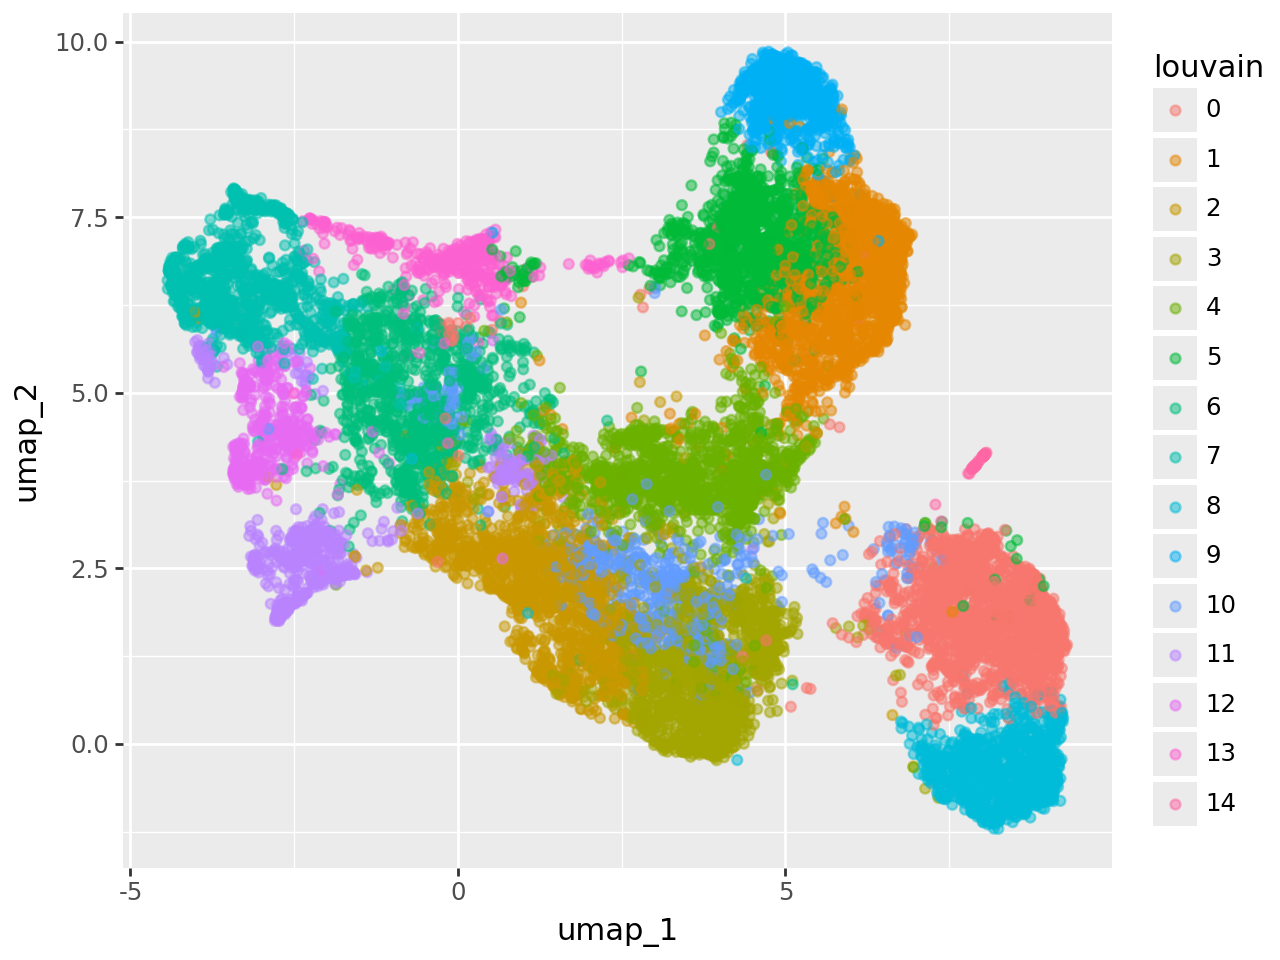

In [119]:
_plot_frame = gg_umap
first_plot = (
    ggplot(_plot_frame, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='louvain'), alpha=.5)
)
first_plot

In [120]:
_to_discard = _plot_frame.query("umap_1 > umap_1.mean() & umap_2 < 0").louvain.unique()
_to_discard

['3', '8', '0', '2', '4']
Categories (15, object): ['0', '1', '2', '3', ..., '11', '12', '13', '14']

In [121]:
discarded_louvain = _to_discard[0]
discarded_louvain

'3'

In [122]:
pheno_by_cluster = {}
for clus, frame in _plot_frame.groupby('louvain'):
    louv_idx = frame.index
    pheno_by_cluster.update({
        clus: {
            pheno: louv_idx.isin(pheno_idx).sum()
            for pheno, pheno_idx
            in unambiguous_observations.items()
        }
    })

pheno_by_cluster

{'0': {'iHSC': np.int64(0),
  'srHSC': np.int64(29),
  'ifnHSC': np.int64(6),
  'qHSC': np.int64(23),
  'preDiff': np.int64(52),
  'pLymph': np.int64(11),
  'pNeuMast': np.int64(4),
  'pEr': np.int64(0),
  'pMk': np.int64(2)},
 '1': {'iHSC': np.int64(0),
  'srHSC': np.int64(12),
  'ifnHSC': np.int64(8),
  'qHSC': np.int64(4),
  'preDiff': np.int64(10),
  'pLymph': np.int64(6),
  'pNeuMast': np.int64(1),
  'pEr': np.int64(0),
  'pMk': np.int64(0)},
 '2': {'iHSC': np.int64(0),
  'srHSC': np.int64(35),
  'ifnHSC': np.int64(8),
  'qHSC': np.int64(19),
  'preDiff': np.int64(237),
  'pLymph': np.int64(8),
  'pNeuMast': np.int64(67),
  'pEr': np.int64(2),
  'pMk': np.int64(8)},
 '3': {'iHSC': np.int64(0),
  'srHSC': np.int64(27),
  'ifnHSC': np.int64(17),
  'qHSC': np.int64(30),
  'preDiff': np.int64(64),
  'pLymph': np.int64(3),
  'pNeuMast': np.int64(12),
  'pEr': np.int64(0),
  'pMk': np.int64(1)},
 '4': {'iHSC': np.int64(0),
  'srHSC': np.int64(17),
  'ifnHSC': np.int64(5),
  'qHSC': np.i

In [123]:
majority_pheno_by_cluster = {}
for clus, votes in pheno_by_cluster.items():
    votes = sorted(votes.items(), key=lambda item: item[1], reverse=True)
    _total = sum(v for _, v in votes)
    relative_votes = [(name, v/_total) for name, v in votes] 
    print(clus, relative_votes)
    majority_pheno_by_cluster.update({clus: relative_votes[0][0]})

0 [('preDiff', np.float64(0.4094488188976378)), ('srHSC', np.float64(0.2283464566929134)), ('qHSC', np.float64(0.18110236220472442)), ('pLymph', np.float64(0.08661417322834646)), ('ifnHSC', np.float64(0.047244094488188976)), ('pNeuMast', np.float64(0.031496062992125984)), ('pMk', np.float64(0.015748031496062992)), ('iHSC', np.float64(0.0)), ('pEr', np.float64(0.0))]
1 [('srHSC', np.float64(0.2926829268292683)), ('preDiff', np.float64(0.24390243902439024)), ('ifnHSC', np.float64(0.1951219512195122)), ('pLymph', np.float64(0.14634146341463414)), ('qHSC', np.float64(0.0975609756097561)), ('pNeuMast', np.float64(0.024390243902439025)), ('iHSC', np.float64(0.0)), ('pEr', np.float64(0.0)), ('pMk', np.float64(0.0))]
2 [('preDiff', np.float64(0.6171875)), ('pNeuMast', np.float64(0.17447916666666666)), ('srHSC', np.float64(0.09114583333333333)), ('qHSC', np.float64(0.049479166666666664)), ('ifnHSC', np.float64(0.020833333333333332)), ('pLymph', np.float64(0.020833333333333332)), ('pMk', np.floa

In [124]:
represented_by_louvain = set(majority_pheno_by_cluster.values())
phenotypes = set(unambiguous_observations)

In [125]:
100 * len(represented_by_louvain.intersection(phenotypes)) / len(phenotypes)

66.66666666666667

In [126]:
phenotypes.difference(represented_by_louvain)

{'ifnHSC', 'pLymph', 'pMk'}

In [127]:
_new_plot = _plot_frame.join(_plot_frame.louvain.map(majority_pheno_by_cluster).to_frame().rename(columns={"louvain": "phenotype"}))
_new_plot.head()

,umap_1,umap_2,louvain,phenotype
AAACCTGAGTTCGATC-1_0,1.678094,2.379958,10,preDiff
AAACCTGCAATCGGTT-1_0,3.786061,0.326149,3,preDiff
AAACCTGCACACGCTG-1_0,-1.435545,3.732314,6,preDiff
AAACCTGCACGGATAG-1_0,-1.639036,3.743245,6,preDiff
AAACCTGCATCATCCC-1_0,-0.696226,4.099241,6,preDiff


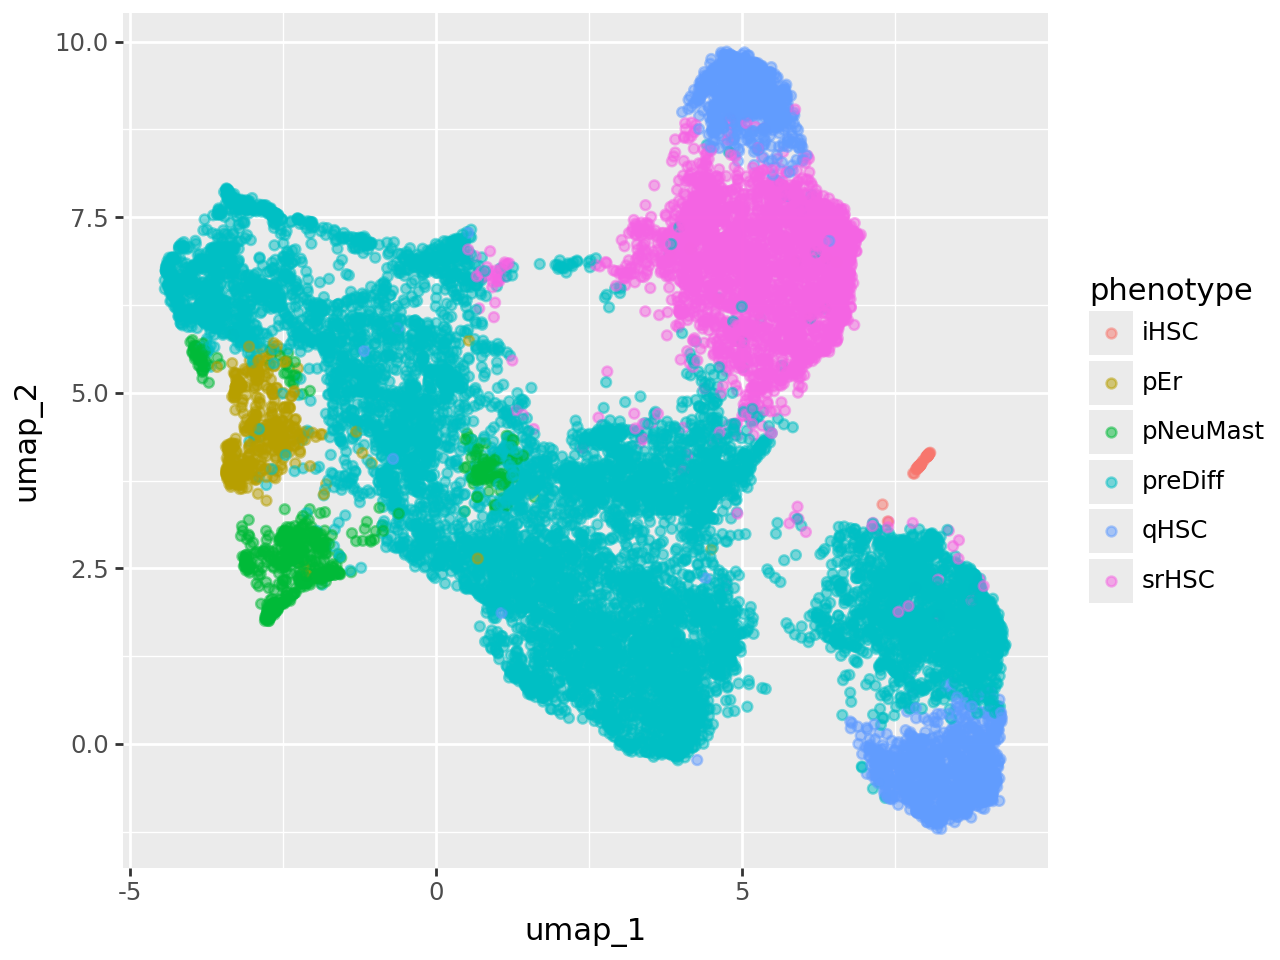

In [128]:
second_plot = (
    ggplot(_new_plot, aes(x=_plot_frame.columns[0], y=_plot_frame.columns[1]))
        + geom_point(aes(color='phenotype'), alpha=.5)
)
second_plot

In [129]:
palette = sns.color_palette('Set2', _plot_frame.louvain.unique().shape[0])
palette.as_hex()

['#66c2a5',
 '#fc8d62',
 '#8da0cb',
 '#e78ac3',
 '#a6d854',
 '#ffd92f',
 '#e5c494',
 '#b3b3b3',
 '#66c2a5',
 '#fc8d62',
 '#8da0cb',
 '#e78ac3',
 '#a6d854',
 '#ffd92f',
 '#e5c494']

In [130]:
final_color_map = dict(zip(_new_plot.phenotype.unique(),palette.as_hex()))
final_color_map

{'preDiff': '#66c2a5',
 'pEr': '#fc8d62',
 'pNeuMast': '#8da0cb',
 'srHSC': '#e78ac3',
 'qHSC': '#a6d854',
 'iHSC': '#ffd92f'}

In [131]:
metadata = pd.DataFrame({
    'label': _new_plot.phenotype,
    'label_color': _new_plot.phenotype.map(final_color_map),
    'louvain': _new_plot.louvain,
})
metadata.loc[:, 'discard'] = False
metadata.loc[metadata.louvain == discarded_louvain, 'discard'] = True
metadata.head()

,label,label_color,louvain,discard
AAACCTGAGTTCGATC-1_0,preDiff,#66c2a5,10,False
AAACCTGCAATCGGTT-1_0,preDiff,#66c2a5,3,True
AAACCTGCACACGCTG-1_0,preDiff,#66c2a5,6,False
AAACCTGCACGGATAG-1_0,preDiff,#66c2a5,6,False
AAACCTGCATCATCCC-1_0,preDiff,#66c2a5,6,False


In [132]:
metadata.discard.value_counts()

discard
False    13487
True      1428
Name: count, dtype: int64